# 03 · Event-aligned responses under each baseline

These are the old analyses of tile ΔF/F aligned to Grating 1 (Stim 2), Grating 2 (Stim 4) and Reward, with and without per-trial prestimulus subtraction, plus pupil aligned to the same events. Each is redrawn under every baseline definition in `SPEC`. With `regress_running = True`, every response uses running-regressed ΔF/F, and an extra section overlays original and regressed responses. Regressed traces are missing within the lag range of the recording edges and wherever speed is missing, so a few edge events can drop out.

- Events come from the row-aligned behaviour table (`behavior_table` in the config). Consecutive active rows count as one onset, and only events whose whole window fits inside the recording are used.
- Prestimulus subtraction centres each trial and trace on its own mean over `[PRESTIM_START_S, 0)`. A trial/trace pair with fewer than `MIN_VALID_FRACTION` valid prestimulus samples is dropped from both the original and the subtracted average.
- Shading is SEM across events in this recording, not across animals. Windows can contain other events, so this is association, not isolation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nlight import analyses, analysis_plots as ap, plotting, recording_comparison, regression, session, state

plotting.use_lab_style()
RECORDINGS = session.load_recordings(Path('../../configs/nlight_recordings.json'))
print('Available:', list(RECORDINGS))

Available: ['corridor2 passive viewing', 'corridor2 baseline', 'passive (4 planes)', 'no puff (2x, 4 planes)', 'puff (2x, 4 planes)']


In [2]:
RECORDING = 'corridor2 passive viewing'   # any name from configs/nlight_recordings.json
# Baseline definitions applied to every analysis below. The first is the "current" method.
SPEC = recording_comparison.BaselineSpec(current_window_s=60, current_percentile=50,
                                         fixed_percentiles=(10,), long_windows_s=(180, 300, 600))
# True: every analysis below uses running-regressed ΔF/F (fitted per baseline method and per tile).
# The originals stay available as s['wf_original'] and each tile's 'dff_original'.
regress_running = True
# Running definition and regression model, shared by notebooks 02-04. threshold is in the
# behaviour table's speed units; check it against the speed histogram in notebook 04.
RUNNING_MODEL = regression.RunningModel(threshold=2.0, min_bout_s=1.0, min_lag_s=-1.0,
                                        max_lag_s=5.0, step_s=0.25, cv_folds=5, cv_gap_s=30.0)
PRE_S, POST_S = 2.0, 20.0
PRESTIM_START_S = -2.0
MIN_VALID_FRACTION = 0.8
SUMMARY_WINDOW_S = (0, 5)     # for the response table
HEATMAP_LIMIT = None          # % dF/F; None = 98th percentile per figure

In [3]:
s = session.open_session(RECORDINGS[RECORDING], SPEC, regress_running=regress_running,
                         running_model=RUNNING_MODEL)
b = s['behavior']
if b is None or not b.onsets:
    raise ValueError(f'{RECORDING} has no behaviour table with events in the config')
print({k: len(v) for k, v in b.onsets.items()}, 'onsets detected')

/Users/megyoung/mini2p-preprocessing/src/nlight/baseline_comparison.py:44: UserWarning: skipping 600 s window: recording is 563 s
  warnings.warn(f"skipping {seconds:g} s window: recording is {duration_s:.0f} s")


{'Grating 1': 18, 'Grating 2': 18, 'Reward': 18} onsets detected


## Whole-FOV event responses: one line per baseline

events_used  mean_response_pct  \
event     method                                                      
Grating 1 Current: 60 s rolling p50           18               0.05   
          Fixed full-recording p10            18               1.02   
          180 s rolling p50                   18               0.11   
          300 s rolling p50                   18               0.15   
Grating 2 Current: 60 s rolling p50           17               0.10   
          Fixed full-recording p10            17               1.05   
          180 s rolling p50                   17               0.15   
          300 s rolling p50                   17               0.17   
Reward    Current: 60 s rolling p50           17              -0.06   
          Fixed full-recording p10            17               0.95   
          180 s rolling p50                   17               0.03   
          300 s rolling p50                   17               0.07   

                                     centred_response_pp  
event     method                                          
Grating 1 Current: 60 s rolling p50                -0.08  
          Fixed full-recording p10                 -0.09  
          180 s rolling p50                        -0.09  
          300 s rolling p50                        -0.09  
Grating 2 Current: 60 s rolling p50                -0.17  
          Fixed full-recording p10                 -0.17  
          180 s rolling p50                        -0.16  
          300 s rolling p50                        -0.17  
Reward    Current: 60 s rolling p50                -0.20  
          Fixed full-recording p10                 -0.17  
          180 s rolling p50                        -0.17  
          300 s rolling p50                        -0.16

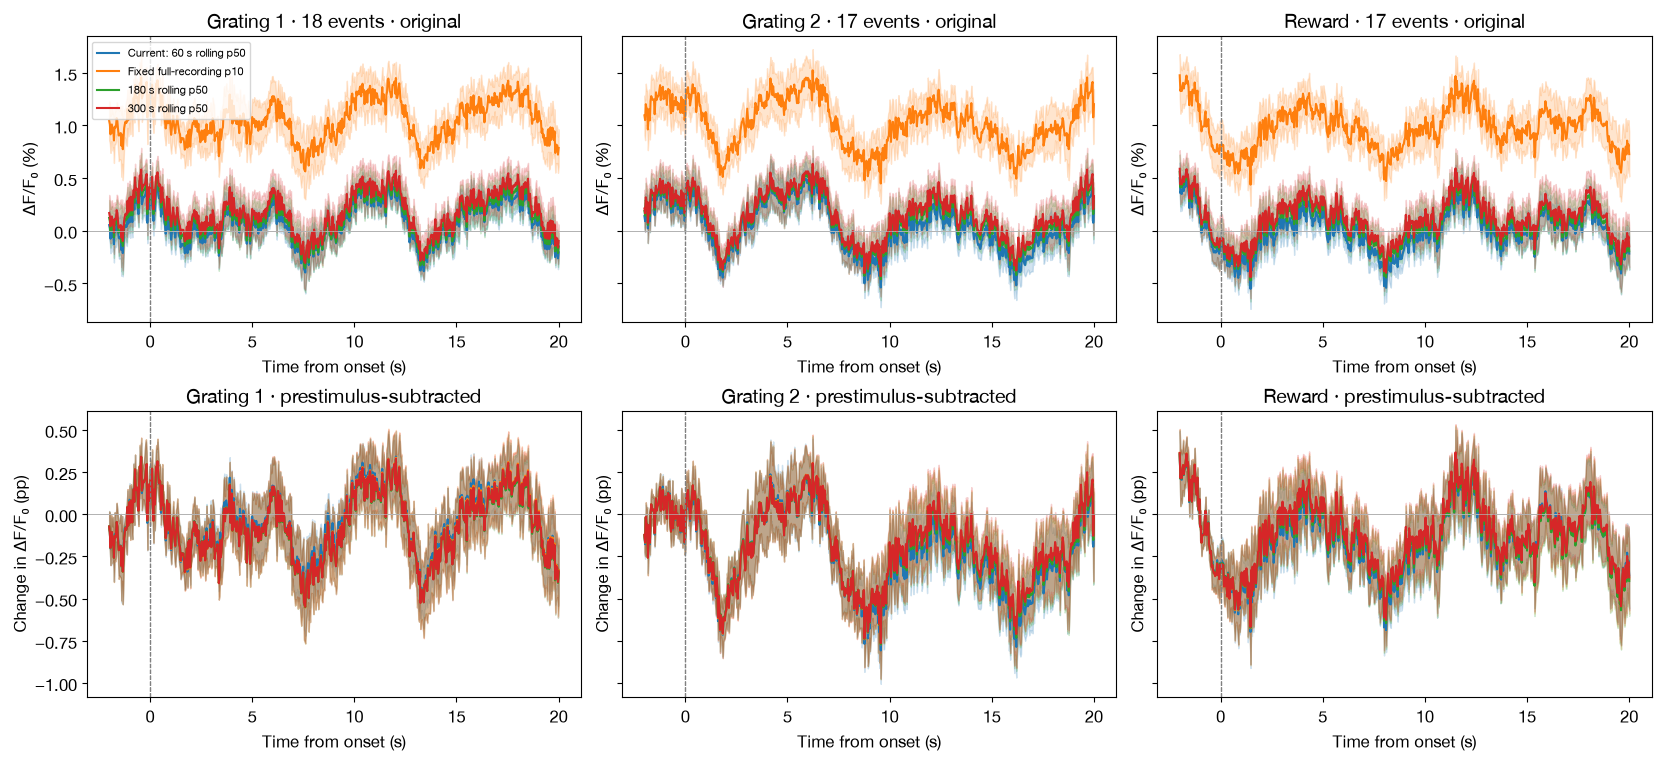

In [4]:
wf = analyses.event_responses(s['wf'], b.onsets, s['fs'], PRE_S, POST_S, PRESTIM_START_S, MIN_VALID_FRACTION)
names = list(wf)
fig, axes = plt.subplots(2, len(names), figsize=(5.5 * len(names), 7.5), sharey='row',
                         constrained_layout=True, squeeze=False)
for j, ev in enumerate(names):
    for color, (m, r) in zip(plotting._colors(len(wf[ev])), wf[ev].items()):
        ap.plot_event_mean(r['relative_s'], r['mean'], r['sem'], axes[0, j], label=m, color=color)
        ap.plot_event_mean(r['relative_s'], r['centred_mean'], r['centred_sem'], axes[1, j], color=color)
    n = len(next(iter(wf[ev].values()))['onsets'])
    axes[0, j].set_title(f'{ev} · {n} events · original')
    axes[1, j].set_title(f'{ev} · prestimulus-subtracted')
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_ylabel('Change in ΔF/F₀ (pp)')
display(analyses.event_summary(wf, SUMMARY_WINDOW_S).round(2))

## Original vs running-regressed event responses (when `regress_running = True`)

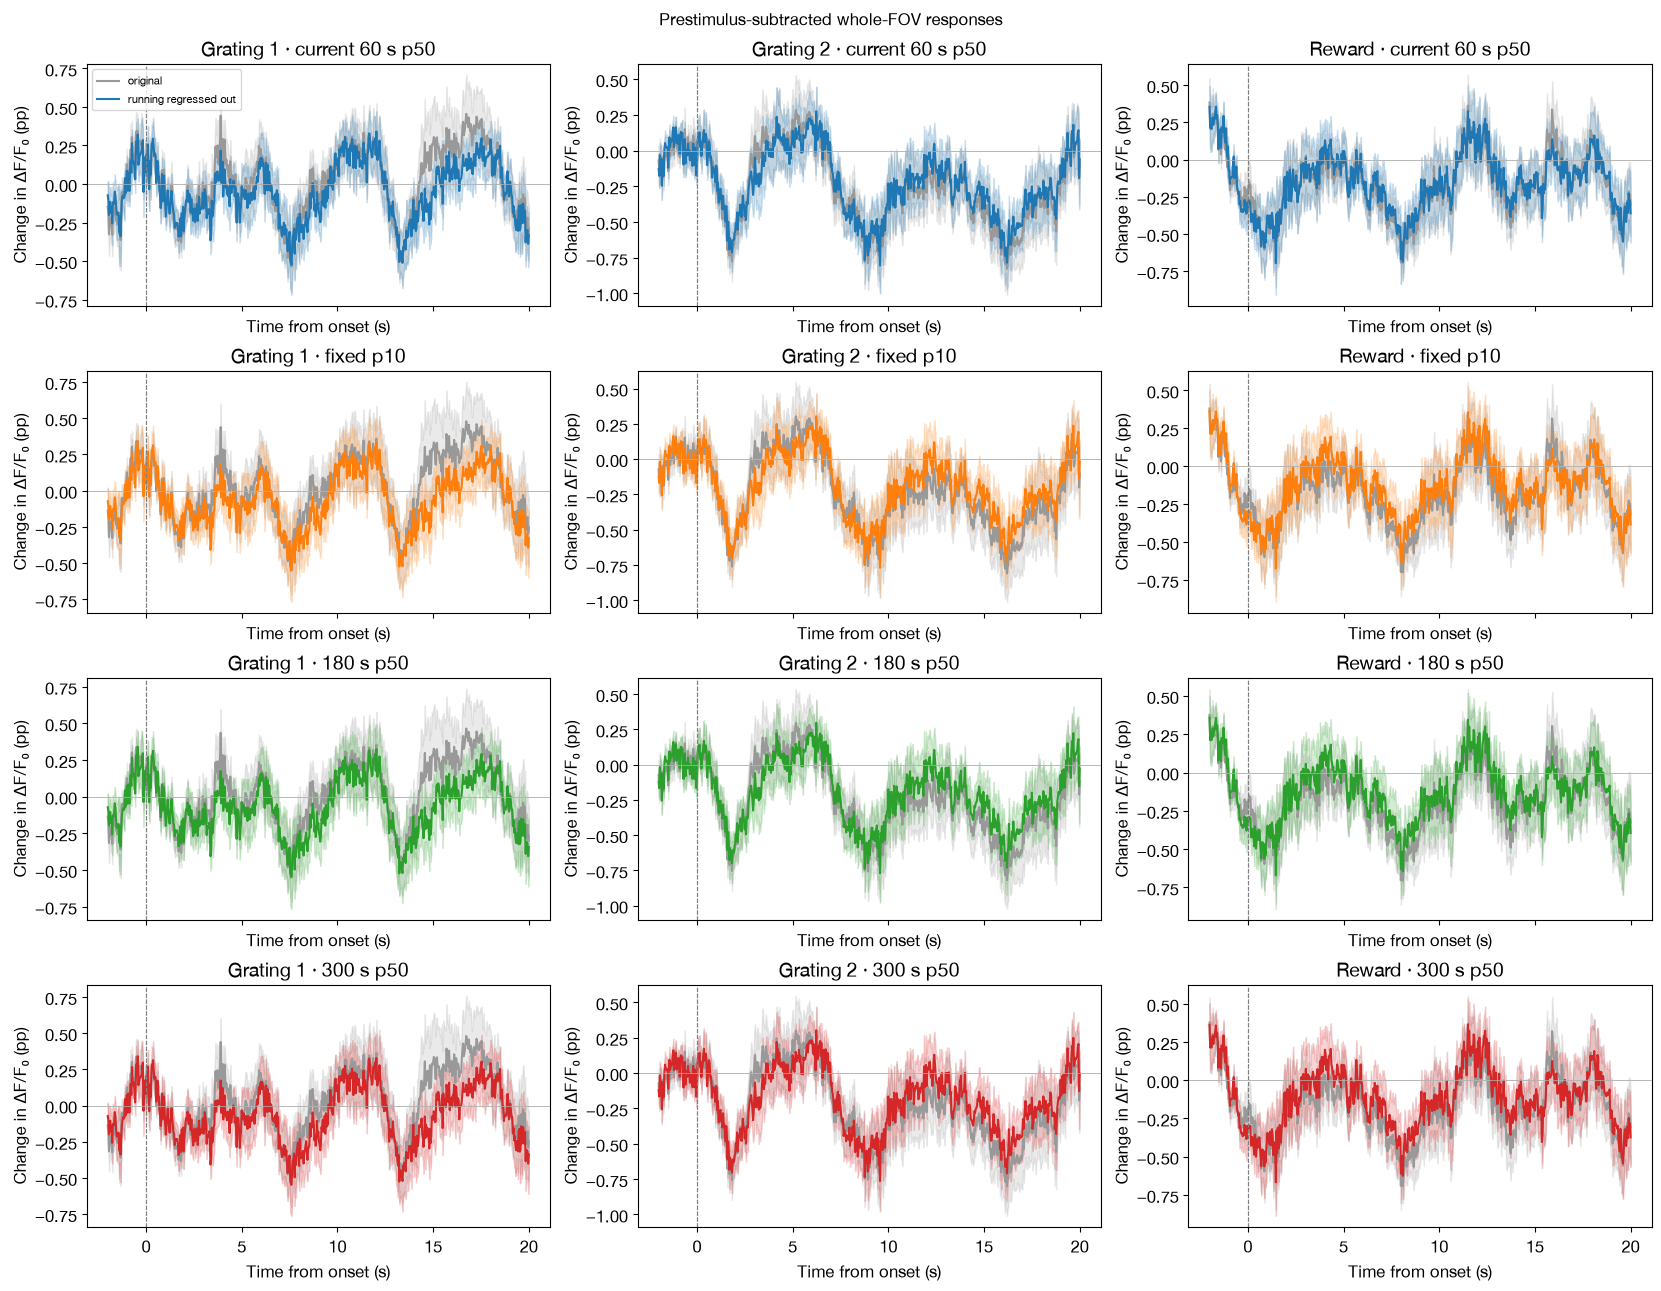

original                    \
                                    events_used mean_response_pct   
event     method                                                    
Grating 1 Current: 60 s rolling p50          18              0.05   
          Fixed full-recording p10           18              1.04   
          180 s rolling p50                  18              0.09   
          300 s rolling p50                  18              0.14   
Grating 2 Current: 60 s rolling p50          17              0.16   
          Fixed full-recording p10           17              1.15   
          180 s rolling p50                  17              0.24   
          300 s rolling p50                  17              0.26   
Reward    Current: 60 s rolling p50          17             -0.08   
          Fixed full-recording p10           17              0.92   
          180 s rolling p50                  17             -0.00   
          300 s rolling p50                  17              0.03   

                                                        running regressed out  \
                                    centred_response_pp           events_used   
event     method                                                                
Grating 1 Current: 60 s rolling p50               -0.03                    18   
          Fixed full-recording p10                -0.04                    18   
          180 s rolling p50                       -0.04                    18   
          300 s rolling p50                       -0.04                    18   
Grating 2 Current: 60 s rolling p50               -0.14                    17   
          Fixed full-recording p10                -0.12                    17   
          180 s rolling p50                       -0.12                    17   
          300 s rolling p50                       -0.12                    17   
Reward    Current: 60 s rolling p50               -0.22                    17   
          Fixed full-recording p10                -0.21                    17   
          180 s rolling p50                       -0.22                    17   
          300 s rolling p50                       -0.21                    17   

                                                                           
                                    mean_response_pct centred_response_pp  
event     method                                                           
Grating 1 Current: 60 s rolling p50              0.05               -0.08  
          Fixed full-recording p10               1.02               -0.09  
          180 s rolling p50                      0.11               -0.09  
          300 s rolling p50                      0.15               -0.09  
Grating 2 Current: 60 s rolling p50              0.10               -0.17  
          Fixed full-recording p10               1.05               -0.17  
          180 s rolling p50                      0.15               -0.16  
          300 s rolling p50                      0.17               -0.17  
Reward    Current: 60 s rolling p50             -0.06               -0.20  
          Fixed full-recording p10               0.95               -0.17  
          180 s rolling p50                      0.03               -0.17  
          300 s rolling p50                      0.07               -0.16

In [5]:
if s['regress_running']:
    orig = analyses.event_responses(s['wf_original'], b.onsets, s['fs'], PRE_S, POST_S, PRESTIM_START_S, MIN_VALID_FRACTION)
    methods = list(s['wf'])
    fig, axes = plt.subplots(len(methods), len(wf), figsize=(5.5 * len(wf), 3.2 * len(methods)),
                             sharex=True, constrained_layout=True, squeeze=False)
    for i, m in enumerate(methods):
        for j, ev in enumerate(wf):
            ap.plot_event_mean(orig[ev][m]['relative_s'], orig[ev][m]['centred_mean'], orig[ev][m]['centred_sem'],
                               axes[i, j], label='original', color='0.6')
            ap.plot_event_mean(wf[ev][m]['relative_s'], wf[ev][m]['centred_mean'], wf[ev][m]['centred_sem'],
                               axes[i, j], label='running regressed out', color=plotting._colors(len(methods))[i])
            axes[i, j].set(title=f'{ev} · {plotting._short(m).replace(chr(10), " ")}', ylabel='Change in ΔF/F₀ (pp)')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle('Prestimulus-subtracted whole-FOV responses')
    display(fig); plt.close(fig)
    display(pd.concat({'original': analyses.event_summary(orig, SUMMARY_WINDOW_S),
                       'running regressed out': analyses.event_summary(wf, SUMMARY_WINDOW_S)}, axis=1).round(2))
else:
    print('Set regress_running = True to compare with running-regressed responses')

## Tile heatmaps: rows = baseline, columns = event

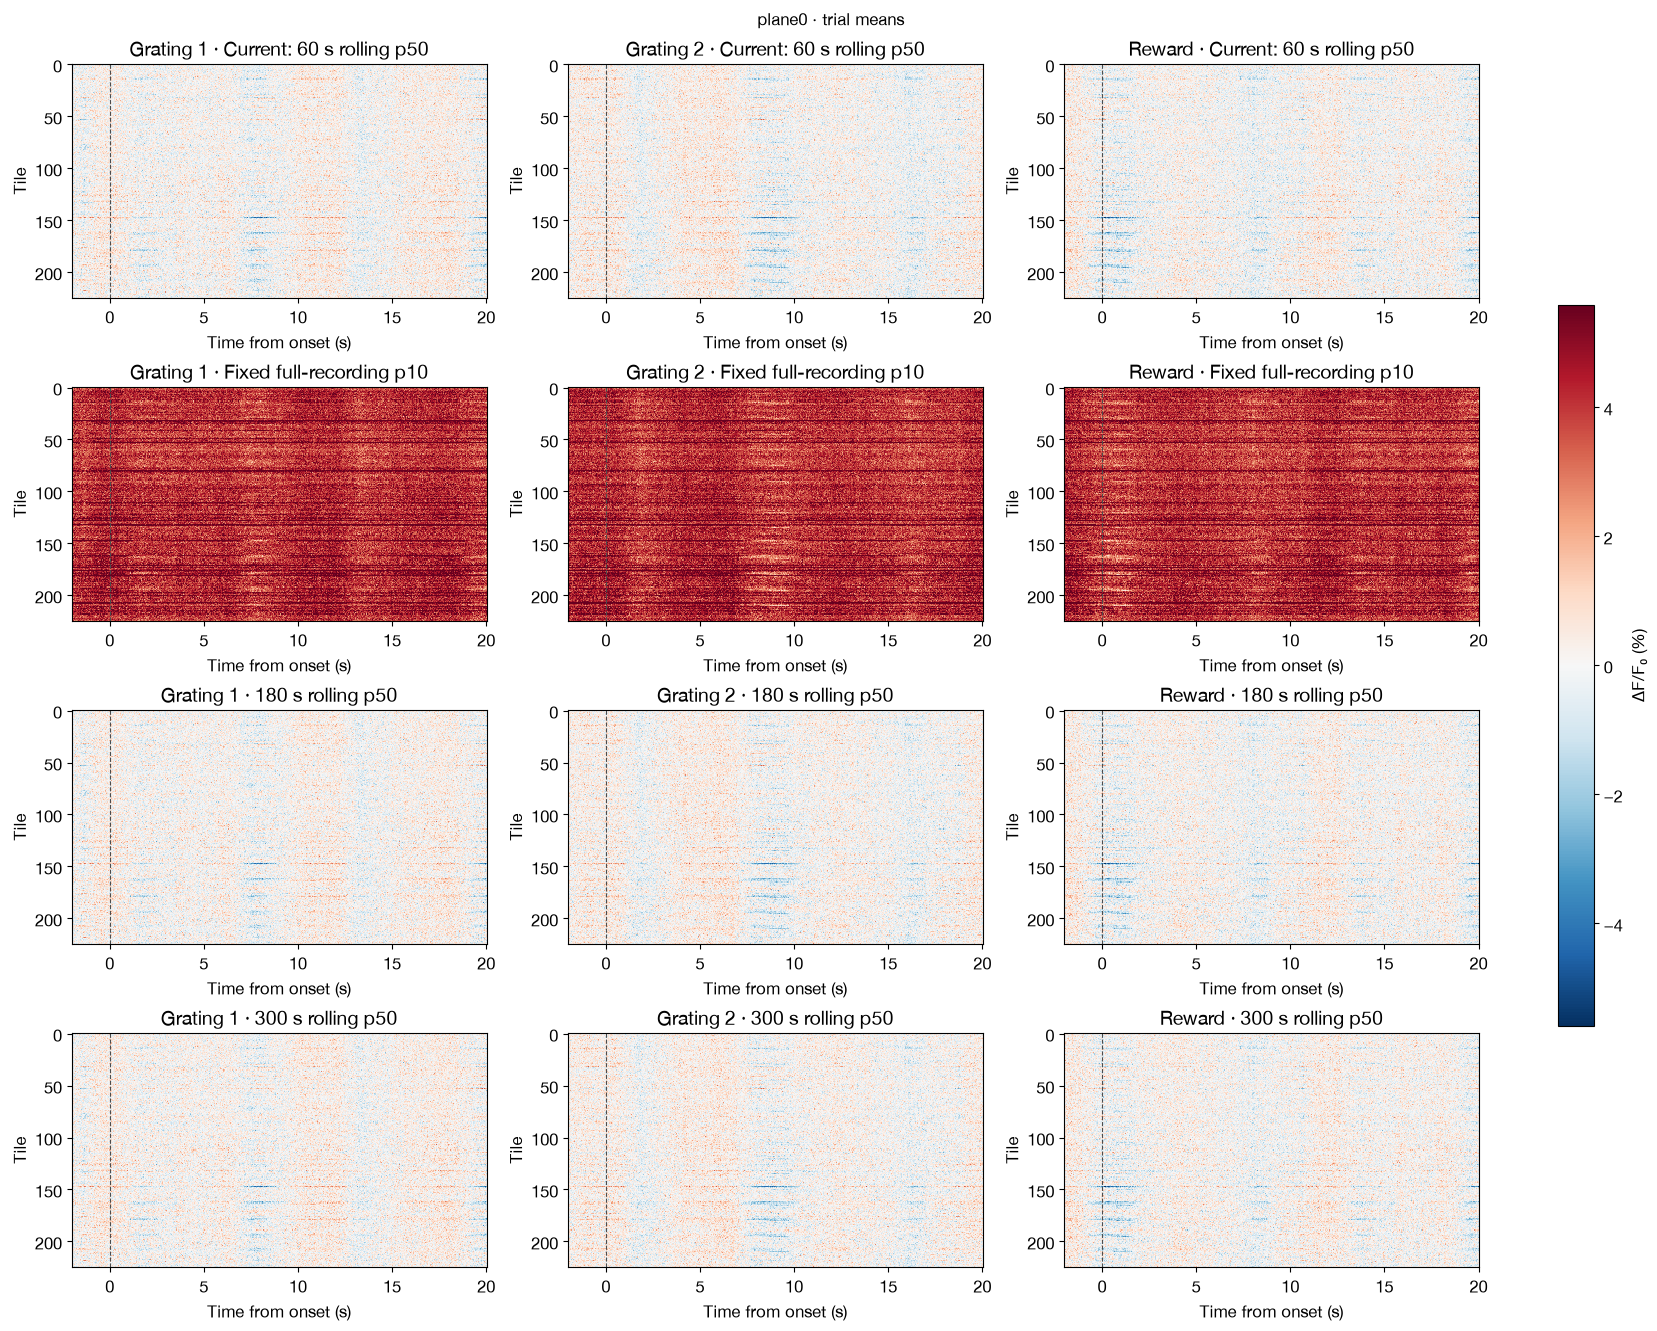

In [6]:
CENTRED = False   # True: prestimulus-subtracted
key = 'centred_mean' if CENTRED else 'mean'
for t in s['tiles']:
    tr = analyses.event_responses(t['dff'], b.onsets, s['fs'], PRE_S, POST_S, PRESTIM_START_S, MIN_VALID_FRACTION)
    methods = list(t['dff'])
    limit = HEATMAP_LIMIT or ap.robust_limit([tr[e][m][key] * 100 for e in tr for m in methods])
    fig, axes = plt.subplots(len(methods), len(tr), figsize=(5.5 * len(tr), 3.3 * len(methods)),
                             constrained_layout=True, squeeze=False)
    for i, m in enumerate(methods):
        for j, ev in enumerate(tr):
            im = ap.plot_event_heatmap(tr[ev][m]['relative_s'], tr[ev][m][key], axes[i, j],
                                       title=f'{ev} · {m}', limit=limit)
    fig.colorbar(im, ax=axes, label='ΔF/F₀ (%)' + (' change from prestimulus' if CENTRED else ''), shrink=0.6)
    fig.suptitle(f"{t['plane'].name} · trial means")
    display(fig); plt.close(fig)

## Pupil and running speed aligned to the same events (independent of baseline)

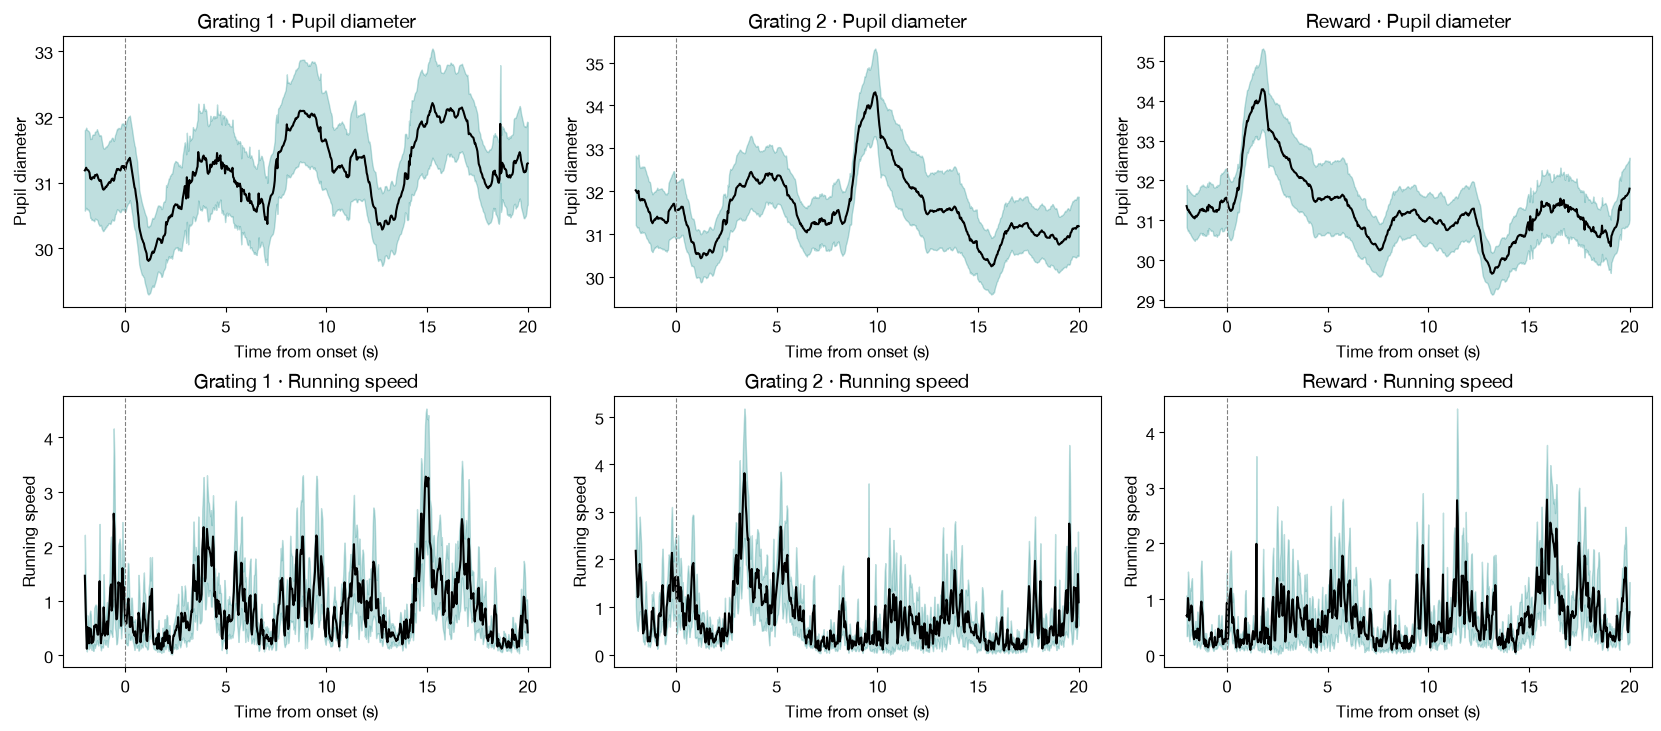

In [7]:
signals = {k: v for k, v in [('Pupil diameter', b.pupil), ('Running speed', b.speed)] if v is not None}
fig, axes = plt.subplots(len(signals), len(b.onsets), figsize=(5.5 * len(b.onsets), 3.6 * len(signals)),
                         constrained_layout=True, squeeze=False)
for i, (label, x) in enumerate(signals.items()):
    r = analyses.event_responses({label: x}, b.onsets, s['fs'], PRE_S, POST_S, PRESTIM_START_S, MIN_VALID_FRACTION)
    for j, ev in enumerate(r):
        res = r[ev][label]
        axes[i, j].fill_between(res['relative_s'], res['mean'] - res['sem'], res['mean'] + res['sem'], color='teal', alpha=.25)
        axes[i, j].plot(res['relative_s'], res['mean'], color='black')
        axes[i, j].axvline(0, color='.5', ls='--', lw=.8)
        axes[i, j].set(title=f'{ev} · {label}', xlabel='Time from onset (s)', ylabel=label)